In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Reporte Ejecutivo de Excepciones:
# Transformamos los hallazgos técnicos en KPI de gestión.
# El objetivo es reducir la carga operativa de conciliación manual al mínimo.

# --- 0. CONFIGURACIÓN E INTEGRACIÓN DE MÓDULOS ---
# Establecemos una estética visual profesional y moderna (Seaborn).
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (14, 6)

# Implementamos rutas dinámicas (Pathlib) para asegurar que el proyecto 
# sea ejecutable en cualquier entorno (Windows/Linux) sin errores de ruta.
base_dir = Path.cwd().resolve()
if base_dir.name == "notebooks":
    base_dir = base_dir.parent

ruta_mayor = base_dir / "data" / "raw" / "libro_mayor.csv"
ruta_conciliados = base_dir / "data" / "processed" / "conciliados_final.csv"
ruta_pendientes = base_dir / "data" / "processed" / "Partidas_Pendientes_Marzo.xlsx"

# Carpeta de salida para evidencias visuales (README y documentación).
ruta_graficos = base_dir / "docs" / "img"
ruta_graficos.mkdir(parents=True, exist_ok=True)

# Control de Disponibilidad de Datos:
# Antes de generar el reporte, validamos la existencia de la evidencia 
# procesada en los notebooks anteriores.
archivos_obligatorios = [ruta_mayor, ruta_pendientes]
faltantes = [str(p) for p in archivos_obligatorios if not p.exists()]
if faltantes:
    raise FileNotFoundError(f"Error Crítico: Faltan archivos de evidencia: {faltantes}")

# Consolidamos la información para el análisis visual
df_mayor = pd.read_csv(ruta_mayor, parse_dates=["fecha_contable"])
df_pend_mayor = pd.read_excel(ruta_pendientes, sheet_name="Revisar_en_Mayor")
df_pend_banco = pd.read_excel(ruta_pendientes, sheet_name="Revisar_en_Banco")

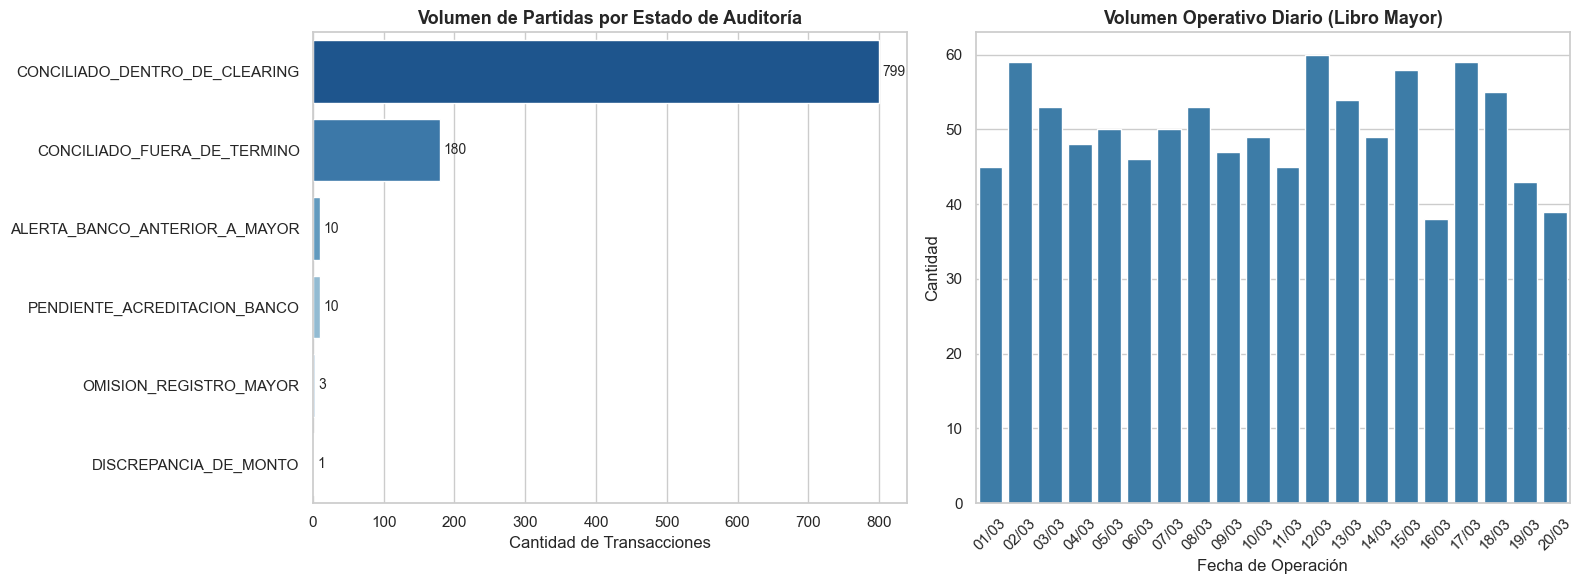

📊 INFORME DE GESTIÓN Y AUDITORÍA FINANCIERA: AUDITSYNC
 Muestra Total Auditada: 1003 operaciones.
 Tasa de Coincidencia (Match Rate): 98.70%
 Conciliados Automáticos en Término (<=72hs): 79.66%
 ⚠️ Monto en Riesgo / Bajo Observación: $10,286,245.43


In [2]:
# --- 1. PROCESAMIENTO DE KPIs MATEMÁTICAMENTE RIGUROSO ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Carga de evidencia final
df_conciliados = pd.read_csv(ruta_conciliados)
total_transacciones = len(df_conciliados)

# Conteos por categoría
n_conciliados_ok = len(df_conciliados[df_conciliados['estado_audit'] == 'CONCILIADO_DENTRO_DE_CLEARING'])
n_fuera_termino = len(df_conciliados[df_conciliados['estado_audit'] == 'CONCILIADO_FUERA_DE_TERMINO'])
n_alerta_fecha = len(df_conciliados[df_conciliados['estado_audit'] == 'ALERTA_BANCO_ANTERIOR_A_MAYOR'])
n_discrepancia = len(df_conciliados[df_conciliados['estado_audit'] == 'DISCREPANCIA_DE_MONTO'])
n_pend_banco = len(df_conciliados[df_conciliados['estado_audit'] == 'PENDIENTE_ACREDITACION_BANCO'])
n_omision_mayor = len(df_conciliados[df_conciliados['estado_audit'] == 'OMISION_REGISTRO_MAYOR'])

# KPIs Fundamentales
tasa_match = ((total_transacciones - n_pend_banco - n_omision_mayor) / total_transacciones)
tasa_conciliacion_directa = (n_conciliados_ok / total_transacciones)

# Monto en Riesgo Financiero
df_observados = df_conciliados[df_conciliados['estado_audit'].isin([
    'CONCILIADO_FUERA_DE_TERMINO', 'ALERTA_BANCO_ANTERIOR_A_MAYOR',
    'DISCREPANCIA_DE_MONTO', 'PENDIENTE_ACREDITACION_BANCO', 'OMISION_REGISTRO_MAYOR'
])].copy()

monto_en_riesgo = np.where(
    df_observados['monto_mayor'].notna(),
    df_observados['monto_mayor'].abs(),
    (df_observados['monto_banco'] * -1).abs()
).sum()

# --- 2. DASHBOARD EJECUTIVO POR ESTADO Y MONTO ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico A: Distribución de Partidas por Estado de Auditoría (Sintaxis actualizada)
resumen_estados = df_conciliados['estado_audit'].value_counts().reset_index()
resumen_estados.columns = ['estado', 'cantidad']

sns.barplot(
    data=resumen_estados,
    x='cantidad',
    y='estado',
    ax=ax1,
    hue='estado',
    palette='Blues_r',
    legend=False
)
ax1.set_title("Volumen de Partidas por Estado de Auditoría", fontsize=13, fontweight="bold")
ax1.set_xlabel("Cantidad de Transacciones")
ax1.set_ylabel("")
for p in ax1.patches:
    width = p.get_width()
    ax1.annotate(f'{int(width)}', (width + 5, p.get_y() + p.get_height() / 2.),
                 ha='left', va='center', fontsize=10)

# Gráfico B: Timeline de Transacciones
col_fecha = "fecha_contable" if "fecha_contable" in df_mayor.columns else "fecha"
df_mayor[col_fecha] = pd.to_datetime(df_mayor[col_fecha])

movimientos_dia = (
    df_mayor.assign(dia=df_mayor[col_fecha].dt.floor("D"))
    .groupby("dia")
    .size()
    .sort_index()
    .reset_index(name="cantidad")
)
movimientos_dia["dia_str"] = movimientos_dia["dia"].dt.strftime("%d/%m")
sns.barplot(data=movimientos_dia, x="dia_str", y="cantidad", ax=ax2, color="#2c7fb8")
ax2.set_title("Volumen Operativo Diario (Libro Mayor)", fontsize=13, fontweight="bold")
ax2.set_ylabel("Cantidad")
ax2.set_xlabel("Fecha de Operación")
ax2.tick_params(axis="x", rotation=45)

# Exportar evidencia visual
ruta_barras_estado = ruta_graficos / "eficacia_motor_conciliacion.png"
ruta_timeline = ruta_graficos / "volumen_transacciones_timeline.png"
fig.savefig(ruta_barras_estado, dpi=160, bbox_inches="tight")

plt.tight_layout()
plt.show()

# --- 3. INFORME EJECUTIVO ---
print("=" * 65)
print("📊 INFORME DE GESTIÓN Y AUDITORÍA FINANCIERA: AUDITSYNC")
print("=" * 65)
print(f" Muestra Total Auditada: {total_transacciones} operaciones.")
print(f" Tasa de Coincidencia (Match Rate): {tasa_match:.2%}")
print(f" Conciliados Automáticos en Término (<=72hs): {tasa_conciliacion_directa:.2%}")
print(f" ⚠️ Monto en Riesgo / Bajo Observación: ${monto_en_riesgo:,.2f}")
print("=" * 65)